Origen de los datos: archive.ics.uci.edu:
* https://archive.ics.uci.edu/

Datasets:
* Vinos: https://archive.ics.uci.edu/dataset/186/wine%2Bquality
* Iris: https://archive.ics.uci.edu/dataset/53/iris




In [ ]:
try:
  from ucimlrepo import fetch_ucirepo
  print('ucimlrep importado')
except:
  print('Instalando ucimlrep...')
  !pip install ucimlrepo
  from ucimlrepo import fetch_ucirepo
  print('ucimlrep importado')

import pandas as pd


# fetch dataset
wine_quality = fetch_ucirepo(id=186)

# data (as pandas dataframes)
X = wine_quality.data.features
y = wine_quality.data.targets

# metadata
print(wine_quality.metadata)

# variable information
print(wine_quality.variables)


ucimlrep importado
{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeli

In [ ]:
# Obtención del df

# Une las características (X) y el objetivo (y) en un único DataFrame
df = pd.concat([wine_quality.data.features, wine_quality.data.targets], axis=1)

# Renombrado de columnas
df.rename(columns={
    'fixed_acidity': 'acidez_fija',
    'volatile_acidity': 'acidez_volatil',
    'citric_acid': 'acido_citrico',
    'residual_sugar': 'azucar_residual',
    'chlorides': 'cloruros',
    'free_sulfur_dioxide': 'dioxido_azufre_libre',
    'total_sulfur_dioxide': 'dioxido_azufre_total',
    'density': 'densidad',
    'pH': 'pH',
    'sulphates': 'sulfatos',
    'alcohol': 'alcohol',
    'quality': 'calidad'
}, inplace=True)

# Ver el resultado
display(df.head())

,acidez_fija,acidez_volatil,acido_citrico,azucar_residual,cloruros,dioxido_azufre_libre,dioxido_azufre_total,densidad,pH,sulfatos,alcohol,calidad
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   acidez_fija           6497 non-null   float64
 1   acidez_volatil        6497 non-null   float64
 2   acido_citrico         6497 non-null   float64
 3   azucar_residual       6497 non-null   float64
 4   cloruros              6497 non-null   float64
 5   dioxido_azufre_libre  6497 non-null   float64
 6   dioxido_azufre_total  6497 non-null   float64
 7   densidad              6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulfatos              6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  calidad               6497 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 609.2 KB


In [ ]:
display(df['calidad'].min())
display(df['calidad'].max())

3

9

# Clasificador: modelo de clasificación supervisada mediante Machine Learning, utilizando el algoritmo Random Forest

X: contiene las características fisicoquímicas del vino, como acidez, azúcar, densidad y alcohol.

y: contiene la calidad del vino que queremos predecir.

train_test_split: reserva el 20 % de los datos para evaluar el modelo con ejemplos que no ha visto durante el entrenamiento.

RandomForestClassifier: combina múltiples árboles de decisión para clasificar los vinos.

SimpleImputer: sustituye posibles valores ausentes por la mediana de cada columna.

class_weight="balanced": ajusta los pesos para tener en cuenta las diferencias en el número de ejemplos de cada clase.

classification_report: muestra precisión (precision), exhaustividad (recall) y F1 para cada categoría de calidad.

Accuracy: 0.6892

Informe de clasificación:
{'3': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 6.0}, '4': {'precision': 0.6, 'recall': 0.06976744186046512, 'f1-score': 0.125, 'support': 43.0}, '5': {'precision': 0.7410071942446043, 'recall': 0.7219626168224299, 'f1-score': 0.7313609467455622, 'support': 428.0}, '6': {'precision': 0.6545718432510885, 'recall': 0.7954144620811288, 'f1-score': 0.7181528662420382, 'support': 567.0}, '7': {'precision': 0.6818181818181818, 'recall': 0.5555555555555556, 'f1-score': 0.6122448979591837, 'support': 216.0}, '8': {'precision': 1.0, 'recall': 0.3333333333333333, 'f1-score': 0.5, 'support': 39.0}, '9': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 1.0}, 'accuracy': 0.6892307692307692, 'macro avg': {'precision': 0.5253424599019821, 'recall': 0.3537190585218447, 'f1-score': 0.38382267299239775, 'support': 1300.0}, 'weighted avg': {'precision': 0.692589262717527, 'recall': 0.6892307692307692, 'f1-score': 0.6748731217888

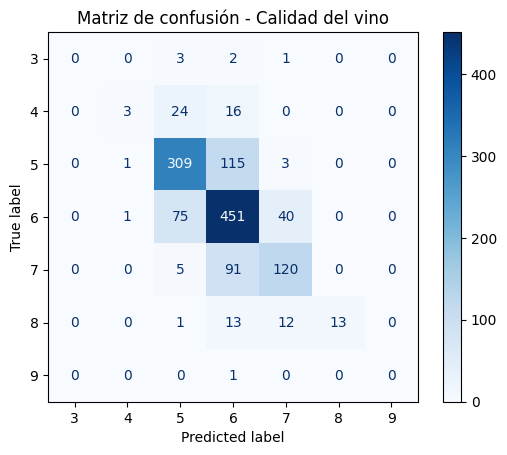

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Separar variables predictoras y objetivo
X = df.drop(columns=["calidad"])
y = df["calidad"]

# 2. Dividir los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42, # Es un número elegido arbitrariamente. Se utiliza siempre el mismo para obtener la misma división de entrenamiento y prueba
    stratify=y # Consigue que se distribuyan correctamente los vinos según su calidad en los set de entrenamiento y prueba
)

# 3. Crear el clasificador
modelo = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=200, # Número de árboles
        random_state=42, # Control de la aleatoriedad
        class_weight="balanced" # balanced, balanced_subsample, None -> Como calcula los pesos de las clases
    )
)

# 4. Entrenar el modelo
modelo.fit(X_train, y_train)

# 5. Realizar predicciones
y_pred = modelo.predict(X_test)

# 6. Evaluar el rendimiento
accuracy = round(accuracy_score(y_test, y_pred), 4)
report = classification_report(y_test, y_pred, zero_division=0, output_dict=True)
print("Accuracy:", accuracy)
print("\nInforme de clasificación:")
print(report)

# Accuracy: Precisión del entrenamiento (redondeado a 4 decimales)

# Precision. De todas las predicciones de una clase, ¿cuántas fueron correctas? Alta = pocas falsas alarmas.
# Recall. De todos los casos reales de una clase, ¿cuántos detectó el modelo? Alto = pocos casos sin detectar.
# F1-score. Equilibrio entre precision y recall. Cuanto más cerca de 1, mejor.
# Support. Número de ejemplos reales de cada clase. Indica cuántos casos se evalua.

# 7. Mostrar la matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)
plt.title("Matriz de confusión - Calidad del vino")
plt.show()

# Obtención de los datos del report

In [ ]:
df_report = pd.DataFrame(report).T
display(df_report)

,precision,recall,f1-score,support
3,0.000000,0.000000,0.000000,6.000000
4,0.600000,0.069767,0.125000,43.000000
5,0.741007,0.721963,0.731361,428.000000
6,0.654572,0.795414,0.718153,567.000000
7,0.681818,0.555556,0.612245,216.000000
8,1.000000,0.333333,0.500000,39.000000
9,0.000000,0.000000,0.000000,1.000000
accuracy,0.689231,0.689231,0.689231,0.689231
macro avg,0.525342,0.353719,0.383823,1300.000000
weighted avg,0.692589,0.689231,0.674873,1300.000000


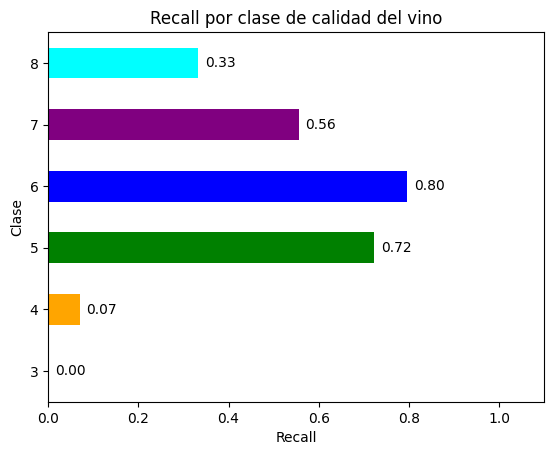

In [ ]:
import matplotlib.pyplot as plt

ax = df_report['recall'].iloc[0:6].plot(
    kind='barh',
    color=['red', 'orange', 'green', 'blue', 'purple',
           'cyan', 'pink', 'gray', 'brown', 'olive']
)

ax.bar_label(ax.containers[0], fmt='%.2f', padding=5)

plt.xlabel('Recall')
plt.ylabel('Clase')
plt.title('Recall por clase de calidad del vino')
plt.xlim(0, 1.1) # Margen en el lado derecho de las barras para los porcentajes
plt.show()

# Predicción

In [ ]:
# Ejemplo con valores ficticios
vino_nuevo = pd.DataFrame([{
    "acidez_fija": 7.4,
    "acidez_volatil": 0.70,
    "acido_citrico": 0.00,
    "azucar_residual": 1.9,
    "cloruros": 0.076,
    "dioxido_azufre_libre": 11,
    "dioxido_azufre_total": 34,
    "densidad": 0.9978,
    "pH": 3.51,
    "sulfatos": 0.56,
    "alcohol": 9.4
}])

prediccion = modelo.predict(vino_nuevo)

print("Calidad predicha:", prediccion[0])

Calidad predicha: 5
